# Machine Learning for Business – CA1
## Metro Interstate Traffic Volume Dataset

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv("Metro_Interstate_Traffic_Volume.csv.gz")

# Display the first five rows
df.head()

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


In [2]:
# Check dataset dimensions
print("Dataset shape:", df.shape)

# Check column names and data types
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (48204, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              61 non-null     object 
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  object 
 6   weather_description  48204 non-null  object 
 7   date_time            48204 non-null  object 
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), object(4)
memory usage: 3.3+ MB

Missing values:
holiday                48143
temp                       0
rain_1h                    0
snow_1h                    0
clouds_all                 0
weather_main               0
weather_description        0
date_time                  0
traff

## 2. Data Cleaning and Preprocessing

In this section, I will check the dataset for missing values and duplicate records. I will also prepare the date column for further analysis.

In [3]:
# Check duplicate records
duplicates = df.duplicated().sum()

print("Number of duplicate records:", duplicates)

Number of duplicate records: 17


In [4]:
# Check holiday values
print(df['holiday'].value_counts(dropna=False))

holiday
NaN                          48143
Labor Day                        7
Thanksgiving Day                 6
Christmas Day                    6
New Years Day                    6
Martin Luther King Jr Day        6
Columbus Day                     5
Veterans Day                     5
Washingtons Birthday             5
Memorial Day                     5
Independence Day                 5
State Fair                       5
Name: count, dtype: int64


In [5]:
# Convert date_time to datetime format
df['date_time'] = pd.to_datetime(df['date_time'])

# Check the date range
print("Start date:", df['date_time'].min())
print("End date:", df['date_time'].max())

# Check the updated data type
print("Date column type:", df['date_time'].dtype)

Start date: 2012-10-02 09:00:00
End date: 2018-09-30 23:00:00
Date column type: datetime64[ns]


## 3. Data Cleaning

In this step, I will handle missing values and duplicate records to prepare the dataset for further analysis.

In [6]:
# Replace missing holiday values
df['holiday'] = df['holiday'].fillna('None')

# Check the results
print(df['holiday'].value_counts())

holiday
None                         48143
Labor Day                        7
Thanksgiving Day                 6
Christmas Day                    6
New Years Day                    6
Martin Luther King Jr Day        6
Columbus Day                     5
Veterans Day                     5
Washingtons Birthday             5
Memorial Day                     5
Independence Day                 5
State Fair                       5
Name: count, dtype: int64


In [7]:
# Check missing values after cleaning
print("Missing values after cleaning:")
print(df.isnull().sum())

# Check dataset dimensions
print("\nFinal dataset shape:", df.shape)

Missing values after cleaning:
holiday                0
temp                   0
rain_1h                0
snow_1h                0
clouds_all             0
weather_main           0
weather_description    0
date_time              0
traffic_volume         0
dtype: int64

Final dataset shape: (48204, 9)


In [8]:
# Remove duplicate records
df = df.drop_duplicates().copy()

# Check the dataset after removing duplicates
print("Dataset shape:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

Dataset shape: (48187, 9)
Remaining duplicates: 0


In [9]:
# Check repeated timestamps
repeated_dates = df['date_time'].duplicated().sum()

print("Repeated timestamps:", repeated_dates)

Repeated timestamps: 7612


In [10]:
# Final data quality check
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate records:", df.duplicated().sum())

Dataset shape: (48187, 9)
Missing values: 0
Duplicate records: 0


## 4. Feature Engineering

In this section, I will create new features from the date and time column to better understand traffic patterns during different hours, days and months.

In [11]:
# Extract date and time features
df['hour'] = df['date_time'].dt.hour
df['day_of_week'] = df['date_time'].dt.dayofweek
df['month'] = df['date_time'].dt.month

# Identify weekends
df['is_weekend'] = df['day_of_week'].isin([5, 6]).astype(int)

# Display the updated dataset
df.head()

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume,hour,day_of_week,month,is_weekend
0,None,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545,9,1,10,0
1,None,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516,10,1,10,0
2,None,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767,11,1,10,0
3,None,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026,12,1,10,0
4,None,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918,13,1,10,0


In [13]:
# Check the new features
print("Dataset shape:", df.shape)

print("\nNew feature statistics:")
print(df[['hour', 'day_of_week', 'month', 'is_weekend']].describe())

print("\nMissing values:")
print(df.isnull().sum().sum())

Dataset shape: (48187, 13)

New feature statistics:
               hour   day_of_week         month    is_weekend
count  48187.000000  48187.000000  48187.000000  48187.000000
mean      11.397742      2.984913      6.505240      0.284309
std        6.940373      2.006041      3.400285      0.451089
min        0.000000      0.000000      1.000000      0.000000
25%        5.000000      1.000000      4.000000      0.000000
50%       11.000000      3.000000      7.000000      0.000000
75%       17.000000      5.000000      9.000000      1.000000
max       23.000000      6.000000     12.000000      1.000000

Missing values:
0


## 5. Exploratory Data Analysis (EDA)

In this section, I will explore traffic patterns using visualisations. I will analyse how traffic volume changes during the day, across weekdays and under different weather conditions.

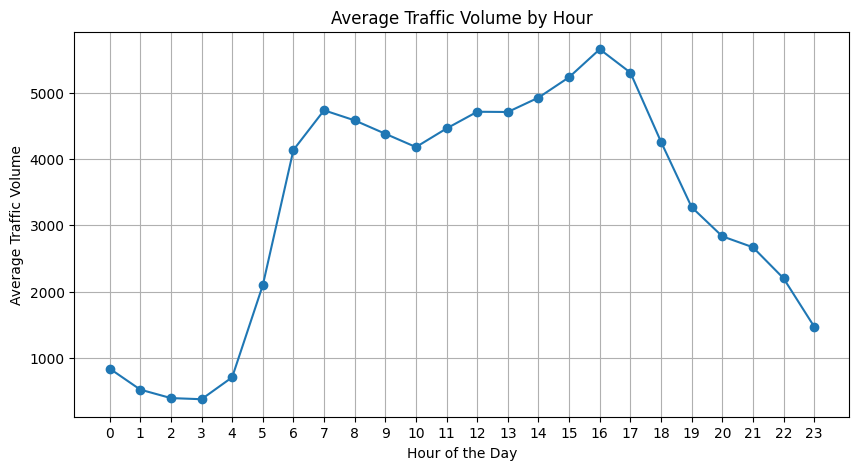

In [15]:
# Average traffic volume by hour
hourly_traffic = df.groupby('hour')['traffic_volume'].mean()

plt.figure(figsize=(10, 5))
hourly_traffic.plot(kind='line', marker='o')

plt.title('Average Traffic Volume by Hour')
plt.xlabel('Hour of the Day')
plt.ylabel('Average Traffic Volume')
plt.xticks(range(0, 24))
plt.grid(True)

plt.show()

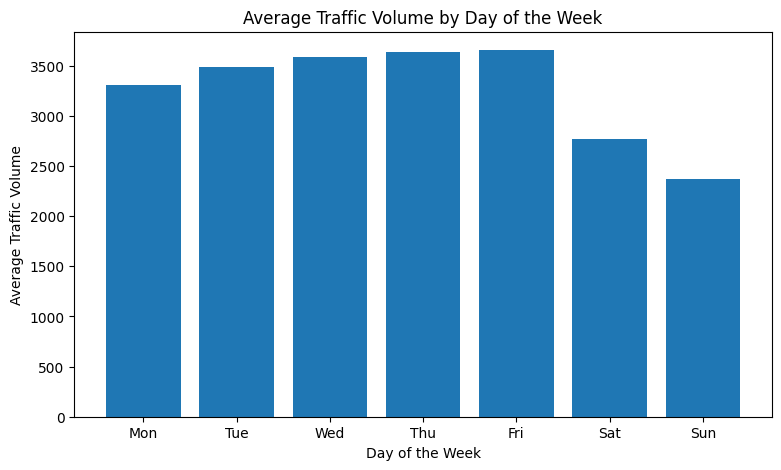

In [16]:
# Average traffic volume by day of the week
weekly_traffic = df.groupby('day_of_week')['traffic_volume'].mean()

days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

plt.figure(figsize=(9, 5))
plt.bar(days, weekly_traffic)

plt.title('Average Traffic Volume by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Average Traffic Volume')

plt.show()

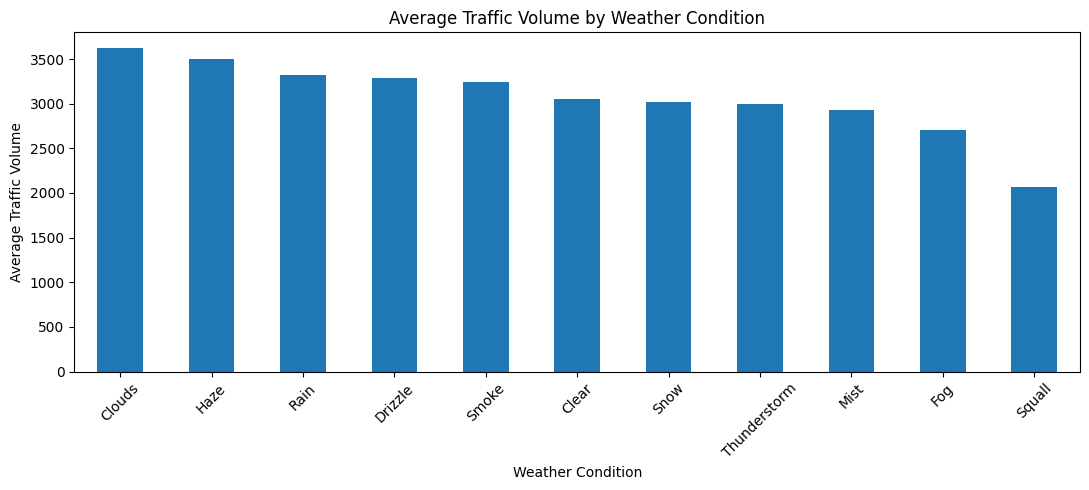

In [17]:
# Average traffic volume by weather condition
weather_traffic = df.groupby('weather_main')['traffic_volume'].mean()

# Sort values
weather_traffic = weather_traffic.sort_values(ascending=False)

# Create chart
plt.figure(figsize=(11, 5))
weather_traffic.plot(kind='bar')

plt.title('Average Traffic Volume by Weather Condition')
plt.xlabel('Weather Condition')
plt.ylabel('Average Traffic Volume')
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### Initial Findings

The analysis shows that average traffic volume is higher during weekdays, especially from Wednesday to Friday.

Traffic volume decreases during weekends, with Sunday showing the lowest average.

This suggests that commuting and regular weekday activities may influence traffic patterns.